In [4]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.datasets import load_diabetes

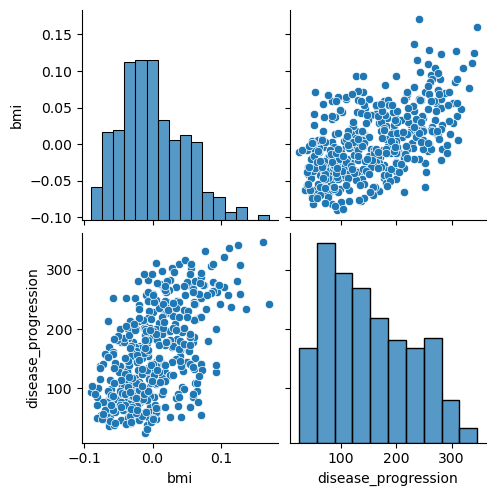

In [5]:
diabetes = load_diabetes()  # data is standardized
df = pd.DataFrame(data=diabetes.data, columns=diabetes.feature_names)[["bmi"]]
df["disease_progression"] = pd.Series(diabetes.target)
g = sns.pairplot(df, vars=df.columns)
plt.show()

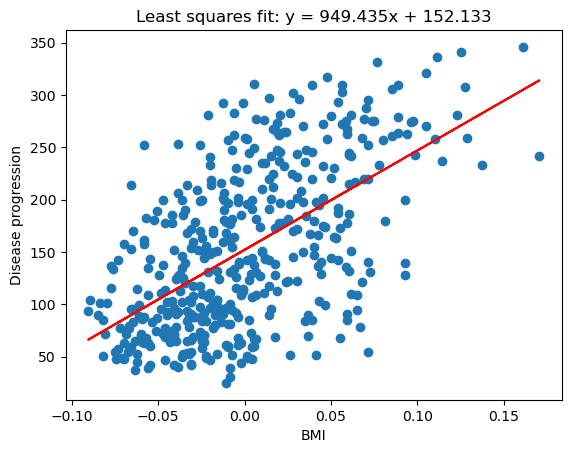

In [6]:
# extract data
x = df["bmi"].values
y = df["disease_progression"].values

# add feature 1 to the data
X = np.c_[np.ones(x.shape), x]

# least squares solution
w = np.dot(np.linalg.inv(np.dot(X.T, X)), np.dot(X.T, y))

# predicted values
y_pred = np.dot(X, w)

# plot regression line and data
plt.title("Least squares fit: y = {:.3f}x + {:.3f}".format(w[1], w[0]))
plt.scatter(df["bmi"], df["disease_progression"])
plt.plot(df["bmi"], y_pred, color="red")
plt.xlabel("BMI")
plt.ylabel("Disease progression")
plt.show()